# Carbonate reef terraces: results

Coral reef terraces built by Quaternary sea-level changes (Pastier et al., 2019),
with goSPL's carbonate module, wave energy and coastal erosion. The runs are
described in `README.md` and in the header of each `input-*.yml`; run
`python scripts/make_inputs.py` and `./run_all.sh` first.

In [1]:
%matplotlib inline
import sys
import matplotlib.pyplot as plt
sys.path.insert(0, 'scripts')
import terraces as T

## The forcing

Relative sea level from the Spratt & Lisiecki (2016) stack over the last 400 kyr.
Each interglacial highstand (MIS 11, 9, 7, 5e and the present) is a chance to
build a reef at the shoreline; the glacial lowstands expose the older reefs.

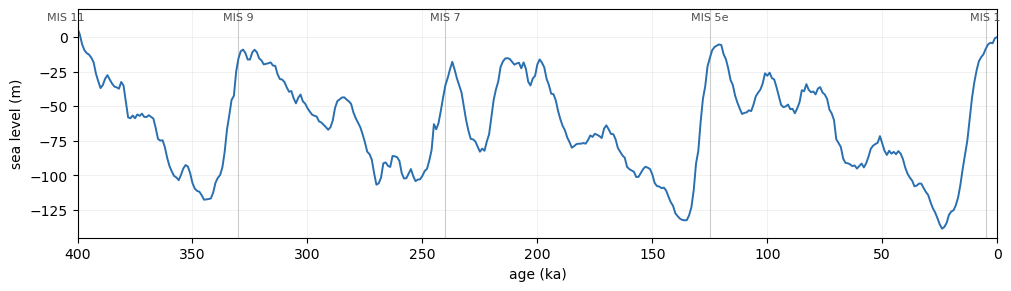

In [2]:
T.sea_level();

## The reference run (100 m, uplift 0.3 mm/yr)

The profile through time: each line is the strip every 50 kyr (darker = older),
the dashed line the initial foundation. The uplift lifts each highstand reef out
of the sea and the next highstand builds a new one lower down: the present-day
profile (black) is a staircase of flat reef tops (the terraces) with a crest at
their outer edge.

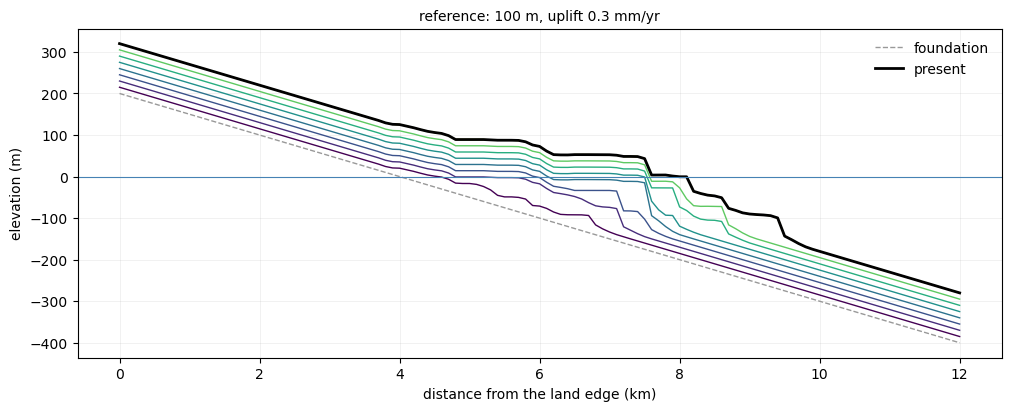

In [3]:
T.profile_evolution('sim_res100', title='reference: 100 m, uplift 0.3 mm/yr');

The stratigraphy along the strip: coloured by lithology (reef framework in pink,
loose carbonate sand light blue, carbonate mud dark blue) and by the age of the
layers (each terrace is younger than the one above it, landward).

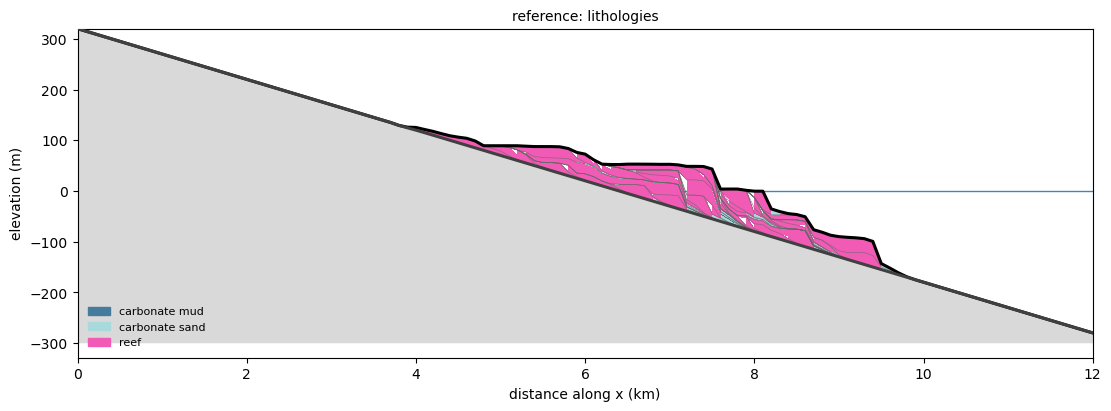

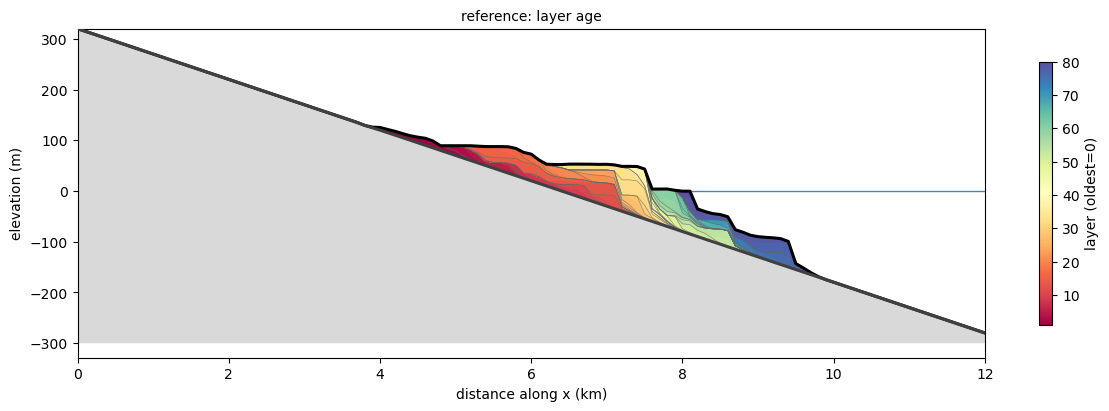

In [4]:
T.section('sim_res100', 'lithologies', title='reference: lithologies')
T.section('sim_res100', 'age', title='reference: layer age');

The carbonate budget: the reef framework and the loose carbonate produced per
step peak at the highstands; the coastal erosion works on the reefs exposed at
the shoreline.

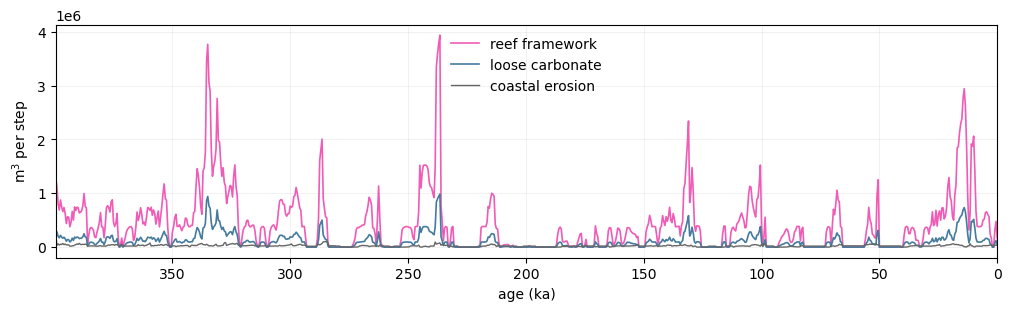

In [5]:
T.budget('summary_res100.jsonl');

## Resolution: 50, 100 and 200 m

The same configuration on three meshes. The terrace levels follow the sea-level
highstands and the uplift, and the three present-day profiles nearly coincide:
the carbonate growth is integrated per node and does not depend on the cell
size. The differences are the position of the steep reef fronts, which moves by
about one cell (they are drawn as sharp steps at 50 m, over two cells at
200 m).

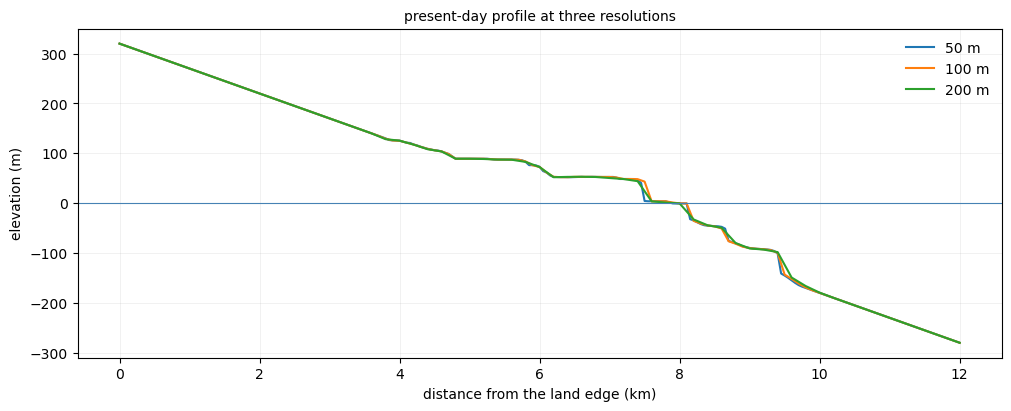

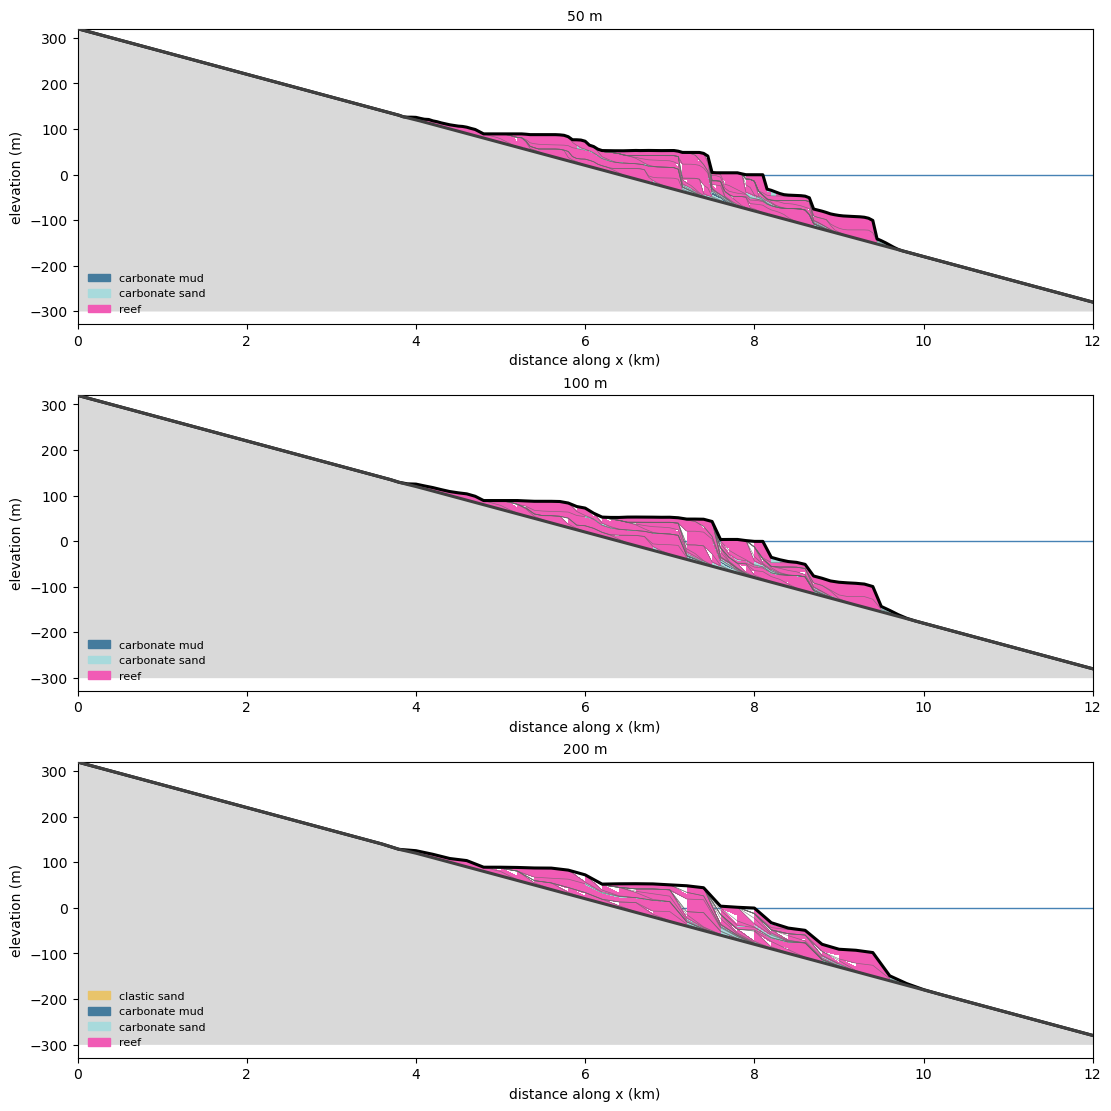

In [6]:
T.compare_profiles(['sim_res050', 'sim_res100', 'sim_res200'], ['50 m', '100 m', '200 m'],
                   title='present-day profile at three resolutions')
fig, ax = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
for a, (sim, res) in zip(ax, (('sim_res050', 50), ('sim_res100', 100), ('sim_res200', 200))):
    T.section(sim, 'lithologies', res=res, ax=a, title='%d m' % res)

## Vertical motion: uplift, stationary, subsidence

Pastier et al. (2019) find that the vertical motion of the coast controls the
architecture first. With uplift the highstand reefs are lifted and preserved as
a staircase; without vertical motion each highstand rebuilds a reef on the same
foundation (few terraces); with subsidence the reefs stack up and the older ones
drown below the present sea level.

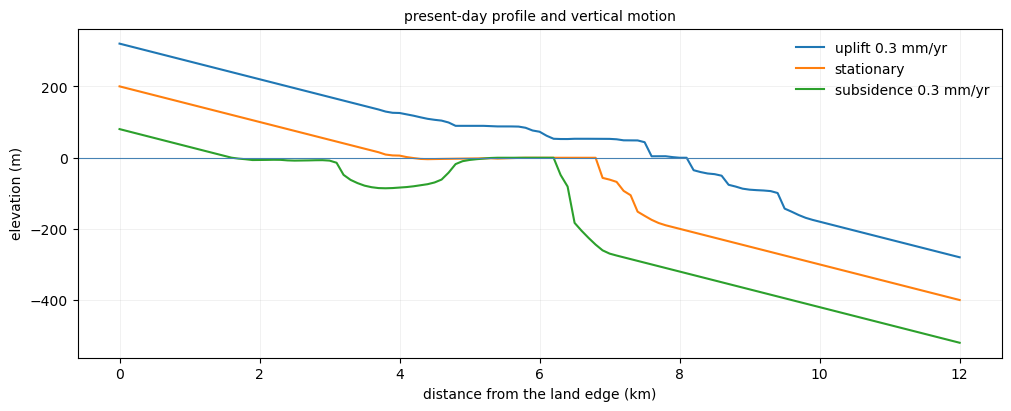

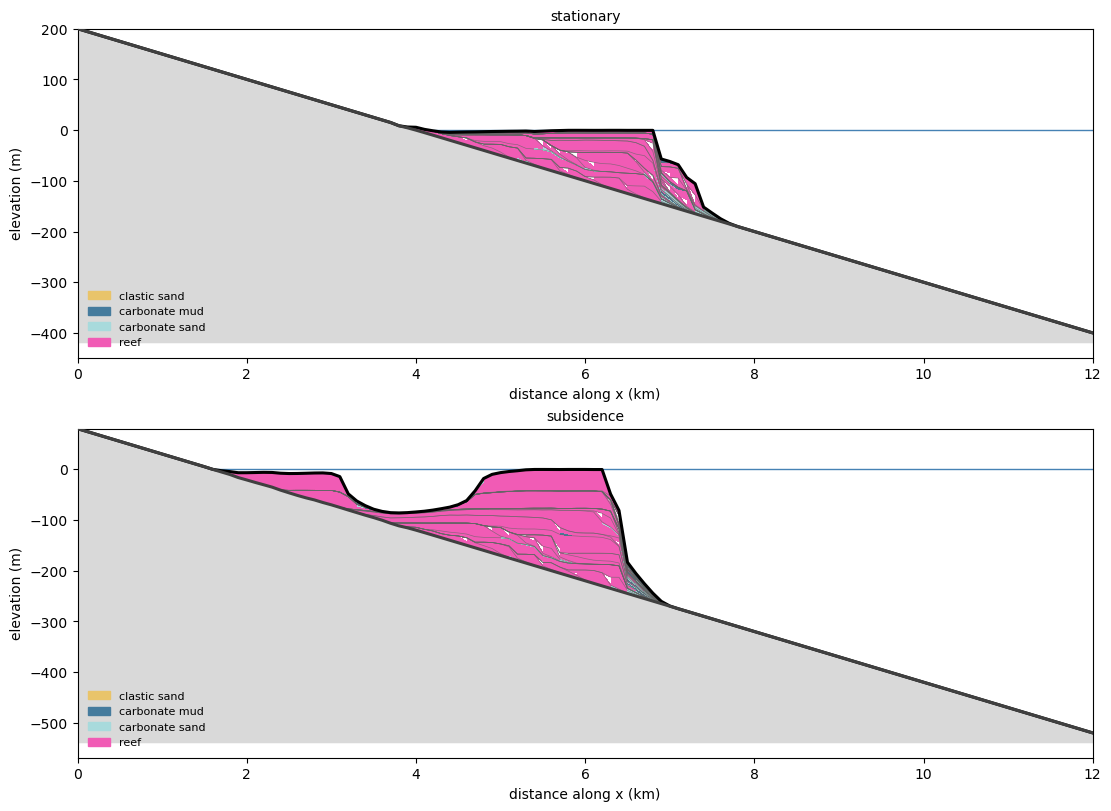

In [7]:
T.compare_profiles(['sim_res100', 'sim_stationary', 'sim_subsidence'],
                   ['uplift 0.3 mm/yr', 'stationary', 'subsidence 0.3 mm/yr'],
                   title='present-day profile and vertical motion')
fig, ax = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
T.section('sim_stationary', 'lithologies', ax=ax[0], title='stationary')
T.section('sim_subsidence', 'lithologies', ax=ax[1], title='subsidence');

## Options: reef alone, with waves, with coastal erosion (subsiding coast)

The options matter where the reef shelters water behind it, so they are compared
on the subsiding coast:

- *reef only*: the factory grows wherever the light allows; the whole platform
  fills up to sea level.
- *+ waves*: the `wave` control keeps the reef on the exposed edge and slows it in
  the sheltered water behind: a barrier reef with a lagoon tens of metres deep.
- *+ coastal erosion* (`input-subsidence.yml`): at 2 mm/yr the waves abrade the
  shallow seafloor and the reef crest a little, but on a sinking coast the
  reef moves away from the erosion faster than it is cut, and the profile
  hardly changes. The erosion matters on the uplifting coast (next section).

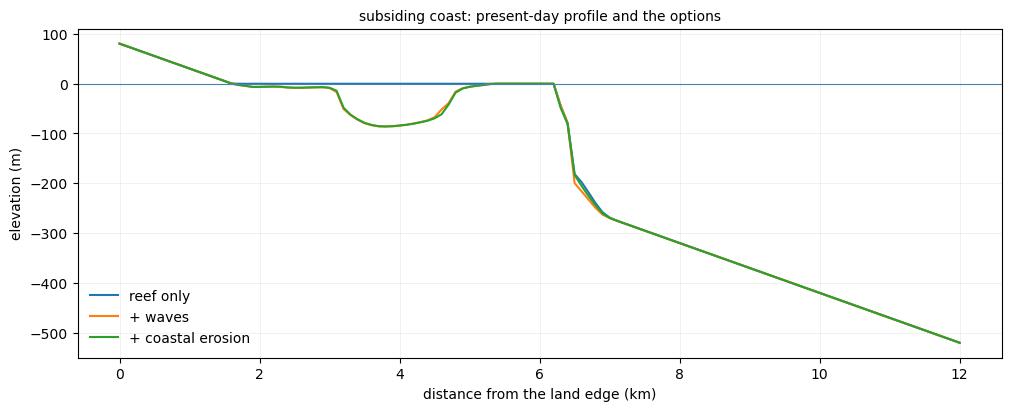

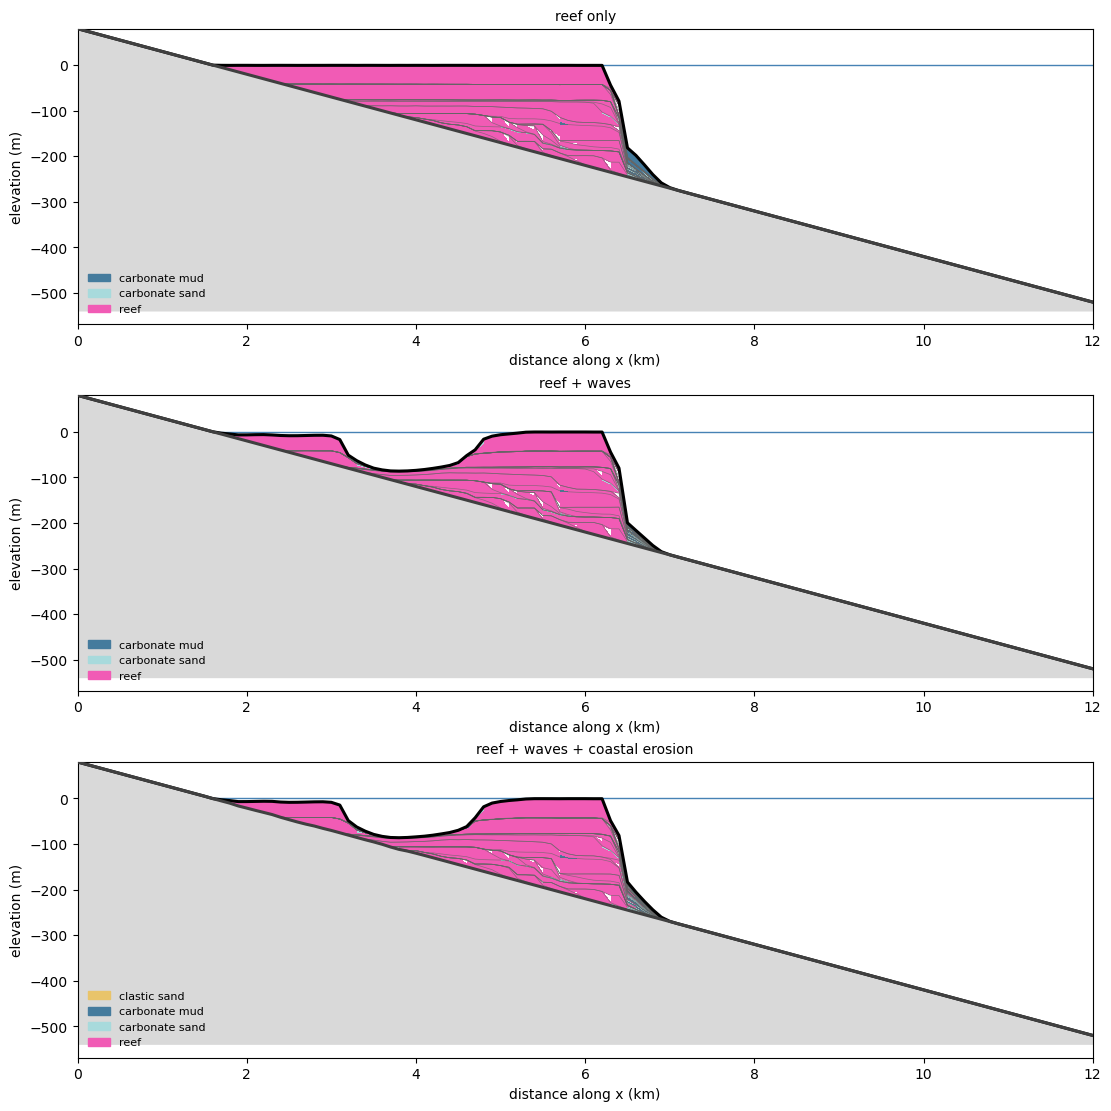

In [8]:
T.compare_profiles(['sim_sub_reefonly', 'sim_sub_waves', 'sim_subsidence'],
                   ['reef only', '+ waves', '+ coastal erosion'],
                   title='subsiding coast: present-day profile and the options')
fig, ax = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
T.section('sim_sub_reefonly', 'lithologies', ax=ax[0], title='reef only')
T.section('sim_sub_waves', 'lithologies', ax=ax[1], title='reef + waves')
T.section('sim_subsidence', 'lithologies', ax=ax[2], title='reef + waves + coastal erosion');

## Coastal erosion strength (uplifting coast)

The reference erodes at most 2 mm/yr (at full wave energy, at sea level; ten
times less in reef framework). Five times stronger erosion (`input-erosion10.yml`,
closer to the erosional potential used by Pastier et al.) cuts back the reef
crests, widens the platforms cut at sea level and smooths the submerged reefs.
Here the platform within 3 m of sea level is twice as wide as in the reference
(400 m, from 8.0 to 8.4 km, against 200 m).

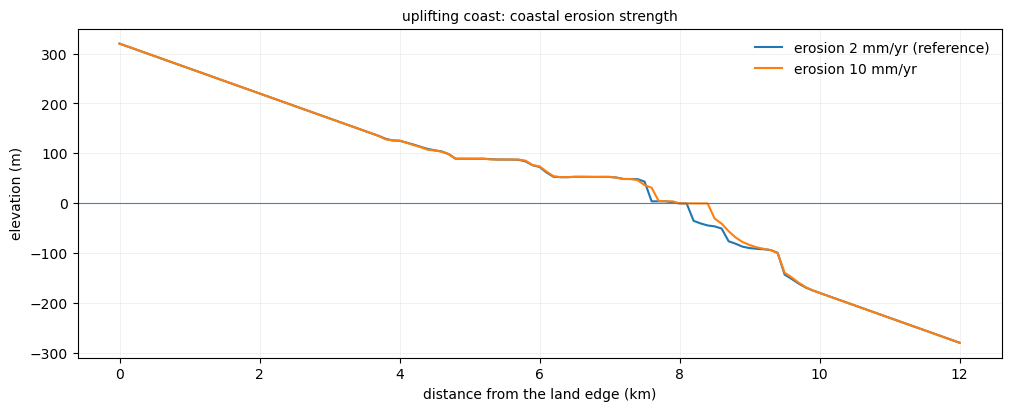

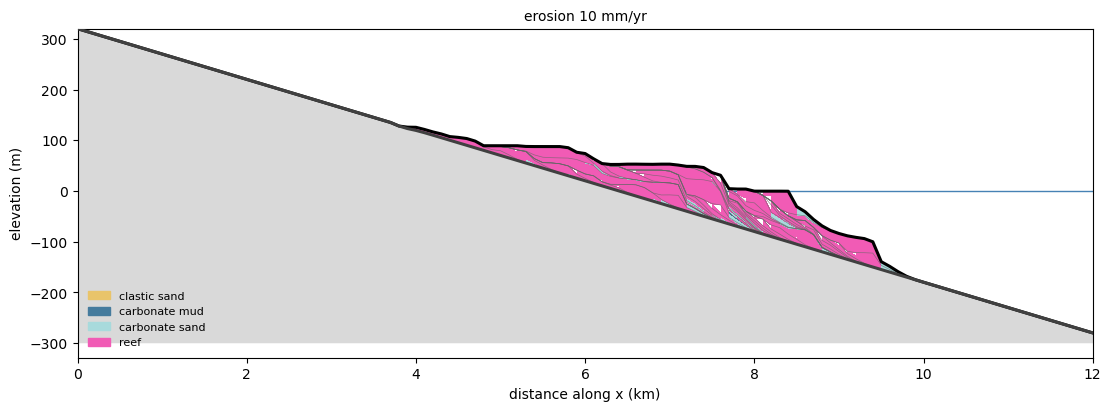

In [9]:
T.compare_profiles(['sim_res100', 'sim_erosion10'], ['erosion 2 mm/yr (reference)', 'erosion 10 mm/yr'],
                   title='uplifting coast: coastal erosion strength')
T.section('sim_erosion10', 'lithologies', title='erosion 10 mm/yr');